<a href="https://colab.research.google.com/github/Van-Sihan/ModuDeepLearning/blob/main/14%EC%9E%A5_%EC%8B%A4%EC%8A%B5(%EB%B3%B5%EC%8A%B5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

!git clone https://github.com/taehojo/data.git

df = pd.read_csv('./data/wine.csv', header=None)

df

Cloning into 'data'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 36 (delta 9), reused 26 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 483.12 KiB | 4.64 MiB/s, done.
Resolving deltas: 100% (9/9), done.


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,0
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,0
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,0
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,0


In [3]:
X = df.iloc[:, 0:12]
y = df.iloc[:, 12]

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

model = Sequential()

model.add(Dense(30, input_dim=12, activation='relu'))
model.add(Dense(12, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.summary()

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=50, batch_size=500, verbose=0, validation_split=0.25)

score = model.evaluate(X_test, y_test)
print('Test accuracy:', score[1])0

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 30)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           372 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 875 (3.42 KB)

 Trainable params: 875 (3.42 KB)

 Non-trainable params: 0 (0.00 B)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9538 - loss: 0.1439 
Test accuracy: 0.9538461565971375


In [6]:
modelpath = "./data/model/all/{epoch:02d}-{val_accuracy:.4f}.keras"

from tensorflow.keras.callbacks import ModelCheckpoint
checkpointer = ModelCheckpoint(filepath=modelpath, verbose=1)

history = model.fit(X_train, y_train, epochs=50, batch_size=500, verbose=0, validation_split=0.25, callbacks=[checkpointer])

score = model.evaluate(X_test, y_test)
print('Test accuracy:', score[1])


Epoch 1: saving model to ./data/model/all/01-0.9462.keras

Epoch 1: finished saving model to ./data/model/all/01-0.9462.keras

Epoch 2: saving model to ./data/model/all/02-0.9492.keras

Epoch 2: finished saving model to ./data/model/all/02-0.9492.keras

Epoch 3: saving model to ./data/model/all/03-0.9485.keras

Epoch 3: finished saving model to ./data/model/all/03-0.9485.keras

Epoch 4: saving model to ./data/model/all/04-0.9469.keras

Epoch 4: finished saving model to ./data/model/all/04-0.9469.keras

Epoch 5: saving model to ./data/model/all/05-0.9485.keras

Epoch 5: finished saving model to ./data/model/all/05-0.9485.keras

Epoch 6: saving model to ./data/model/all/06-0.9492.keras

Epoch 6: finished saving model to ./data/model/all/06-0.9492.keras

Epoch 7: saving model to ./data/model/all/07-0.9485.keras

Epoch 7: finished saving model to ./data/model/all/07-0.9485.keras

Epoch 8: saving model to ./data/model/all/08-0.9508.keras

Epoch 8: finished saving model to ./data/model/all/

In [8]:
history = model.fit(X_train, y_train, epochs=2000, batch_size=500, verbose=0, validation_split=0.25)

hist_df = pd.DataFrame(history.history) #첫 번째 history 가 model.fit / 두 번째 .history 가 model fit 의 개체 속성들의 딕셔너리
hist_df


,accuracy,loss,val_accuracy,val_loss
0,0.982807,0.057336,0.970000,0.077198
1,0.982551,0.056895,0.977692,0.067954
2,0.982294,0.055961,0.976154,0.068254
3,0.982037,0.055898,0.975385,0.068471
4,0.982294,0.055770,0.973846,0.070425
...,...,...,...,...
1995,0.989736,0.033046,0.987692,0.066551
1996,0.989222,0.030919,0.986923,0.071838
1997,0.992045,0.027708,0.986923,0.074375
1998,0.992302,0.025341,0.989231,0.071086


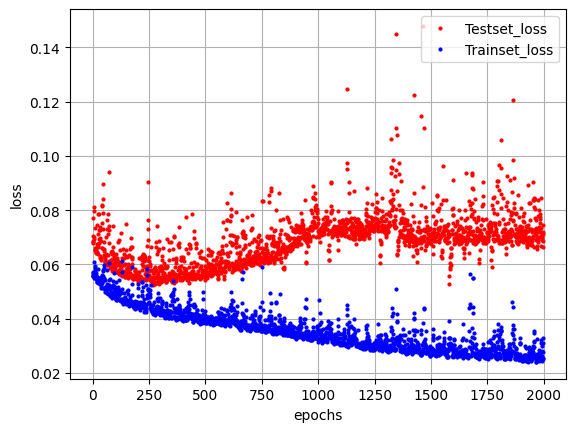

In [12]:
y_vloss = hist_df['val_loss']
y_loss = hist_df['loss']

import numpy as np
import matplotlib.pyplot as plt

x_len = np.arange(len(y_loss))
plt.plot(x_len, y_vloss, "o", c="red", markersize=2, label='Testset_loss')
plt.plot(x_len, y_loss, "o", c="blue", markersize=2, label='Trainset_loss')

plt.legend(loc='upper right')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.grid()
plt.show()